# NewsScope - 01. Exploratory Data Analysis (EDA)

This notebook performs exploratory data analysis on the news article dataset across eight structured sections:
1. **Dataset Overview**
2. **Dataset Distribution**
3. **Missing Values Analysis**
4. **Duplicate Records Analysis**
5. **Text Length Analysis**
6. **Word Frequency Analysis**
7. **Data Visualisation**
8. **Exploration Findings**

### Setup & Data Loading
Import required libraries, download NLTK corpora, load `train_df` and `test_df`, and define category labels.

In [1]:
import os
import re
import string
from collections import Counter

import matplotlib.pyplot as plt
import nltk
from nltk.corpus import stopwords
import numpy as np
import pandas as pd
from datasets import load_dataset

# Download NLTK resources
nltk.download("punkt", quiet=True)
nltk.download("punkt_tab", quiet=True)
nltk.download("stopwords", quiet=True)

# Locate data paths (handles execution from repo root or notebooks/ folder)
raw_dir = (
    os.path.abspath(os.path.join(os.getcwd(), "..", "data", "raw"))
    if os.path.basename(os.getcwd()) == "notebooks"
    else os.path.abspath("data/raw")
)
train_csv = os.path.join(raw_dir, "train.csv")
test_csv = os.path.join(raw_dir, "test.csv")

# Load train_df and test_df from local CSV if present, otherwise from Hugging Face
if os.path.exists(train_csv) and os.path.exists(test_csv):
    train_df = pd.read_csv(train_csv)
    test_df = pd.read_csv(test_csv)
else:
    try:
        ds = load_dataset("fancyzhx/ag_news")
    except Exception:
        ds = load_dataset("ag_news")
    train_df = ds["train"].to_pandas()
    test_df = ds["test"].to_pandas()
    os.makedirs(raw_dir, exist_ok=True)
    train_df.to_csv(train_csv, index=False)
    test_df.to_csv(test_csv, index=False)

# Define AG News class label mapping
label_mapping = {
    0: "World",
    1: "Sports",
    2: "Business",
    3: "Sci/Tech",
}

# Map numerical labels to readable category names
train_df["category"] = train_df["label"].map(label_mapping)
test_df["category"] = test_df["label"].map(label_mapping)

print("train_df and test_df successfully loaded and defined!")
print(f"train_df shape: {train_df.shape}")
print(f"test_df shape:  {test_df.shape}")

train_df and test_df successfully loaded and defined!
train_df shape: (120000, 3)
test_df shape:  (7600, 3)


## 1. Dataset Overview
Examine dataset shapes, schema, column data types, memory usage, and inspect sample records from both training and test sets.

In [2]:
# 1. Dataset Overview
print("=== Training Set Shape ===")
print(train_df.shape)
print("\n=== Test Set Shape ===")
print(test_df.shape)

print("\n=== Training Set Info ===")
train_df.info()

print("\n=== First 5 Training Records ===")
display(train_df.head())

print("\n=== First 5 Test Records ===")
display(test_df.head())

=== Training Set Shape ===
(120000, 3)

=== Test Set Shape ===
(7600, 3)

=== Training Set Info ===
<class 'pandas.DataFrame'>
RangeIndex: 120000 entries, 0 to 119999
Data columns (total 3 columns):
 #   Column    Non-Null Count   Dtype
---  ------    --------------   -----
 0   text      120000 non-null  str  
 1   label     120000 non-null  int64
 2   category  120000 non-null  str  
dtypes: int64(1), str(2)
memory usage: 30.6 MB

=== First 5 Training Records ===


,text,label,category
0,Wall St. Bears Claw Back Into the Black (Reute...,2,Business
1,Carlyle Looks Toward Commercial Aerospace (Reu...,2,Business
2,Oil and Economy Cloud Stocks' Outlook (Reuters...,2,Business
3,Iraq Halts Oil Exports from Main Southern Pipe...,2,Business
4,"Oil prices soar to all-time record, posing new...",2,Business



=== First 5 Test Records ===


,text,label,category
0,Fears for T N pension after talks Unions repre...,2,Business
1,The Race is On: Second Private Team Sets Launc...,3,Sci/Tech
2,Ky. Company Wins Grant to Study Peptides (AP) ...,3,Sci/Tech
3,Prediction Unit Helps Forecast Wildfires (AP) ...,3,Sci/Tech
4,Calif. Aims to Limit Farm-Related Smog (AP) AP...,3,Sci/Tech


## 2. Dataset Distribution
Analyze the class distribution across all categories in both the training and test sets to check for class balance.

In [3]:
# Category distribution count and percentage
category_order = list(label_mapping.values())

train_dist = pd.DataFrame({
    "Count": train_df["category"].value_counts().reindex(category_order),
    "Percentage (%)": (train_df["category"].value_counts(normalize=True).reindex(category_order) * 100).round(2)
})

test_dist = pd.DataFrame({
    "Count": test_df["category"].value_counts().reindex(category_order),
    "Percentage (%)": (test_df["category"].value_counts(normalize=True).reindex(category_order) * 100).round(2)
})

print("=== Train Category Distribution ===")
display(train_dist)

print("\n=== Test Category Distribution ===")
display(test_dist)

=== Train Category Distribution ===


,Count,Percentage (%)
category,,
World,30000,25.0
Sports,30000,25.0
Business,30000,25.0
Sci/Tech,30000,25.0



=== Test Category Distribution ===


,Count,Percentage (%)
category,,
World,1900,25.0
Sports,1900,25.0
Business,1900,25.0
Sci/Tech,1900,25.0


## 3. Missing Values Analysis
Verify data completeness by checking for missing (null/NaN) values in text and label columns.

In [4]:
# Missing values check
for name, df in [("train_df", train_df), ("test_df", test_df)]:
    print(f"\n{name} missing values:")
    print(df[["text", "label", "category"]].isna().sum())

print("\nSummary: Both datasets are 100% complete with 0 missing values.")


train_df missing values:
text        0
label       0
category    0
dtype: int64

test_df missing values:
text        0
label       0
category    0
dtype: int64

Summary: Both datasets are 100% complete with 0 missing values.


## 4. Duplicate Records Analysis
Check for duplicate news texts within each dataset as well as cross-split duplicates (leakage between train and test).

In [5]:
# Duplicate articles and exact records within each dataset
for name, df in [("train_df", train_df), ("test_df", test_df)]:
    print(f"\n{name}:")
    print("Repeated article rows (same text):", df["text"].duplicated().sum())
    print(
        "Repeated record rows (same text and label):",
        df.duplicated(subset=["text", "label"]).sum(),
    )

# Articles appearing in both datasets (exact text match)
train_texts = set(train_df["text"].dropna())
test_texts = set(test_df["text"].dropna())
shared_texts = train_texts & test_texts

print("\nAcross train and test:")
print("Unique articles present in both:", len(shared_texts))
print("Test rows whose article also appears in train:", test_df["text"].isin(shared_texts).sum())
print(
    "Matching text-and-label rows in test:",
    test_df[["text", "label"]].merge(
        train_df[["text", "label"]].drop_duplicates(),
        on=["text", "label"],
    ).shape[0],
)


train_df:
Repeated article rows (same text): 0
Repeated record rows (same text and label): 0

test_df:
Repeated article rows (same text): 0
Repeated record rows (same text and label): 0

Across train and test:
Unique articles present in both: 0
Test rows whose article also appears in train: 0
Matching text-and-label rows in test: 0


## 5. Text Length Analysis
Analyze the distribution of word counts and character counts, identify outlier articles using the IQR method, and compare average article lengths across categories.

In [6]:
# Compute word and character counts
train_df["word_count"] = train_df["text"].str.split().str.len()
train_df["char_count"] = train_df["text"].str.len()
test_df["word_count"] = test_df["text"].str.split().str.len()
test_df["char_count"] = test_df["text"].str.len()

print("=== Word Count Statistics (train_df) ===")
print(train_df["word_count"].describe())

print("\n=== Character Count Statistics (train_df) ===")
print(train_df["char_count"].describe())

# Identify outliers using the 1.5 * IQR rule
word_counts = train_df["word_count"].dropna()
q1, q3 = word_counts.quantile([0.25, 0.75])
iqr = q3 - q1
lower_bound, upper_bound = q1 - 1.5 * iqr, q3 + 1.5 * iqr
outliers = train_df[
    (train_df["word_count"] < lower_bound) | (train_df["word_count"] > upper_bound)
]
print(f"\nUnusually short or long articles (IQR outliers): {len(outliers)}")
print("Shortest 3 articles:")
display(outliers.nsmallest(3, "word_count")[["word_count", "category", "text"]])
print("Longest 3 articles:")
display(outliers.nlargest(3, "word_count")[["word_count", "category", "text"]])

# Average word count by category
category_means = train_df.groupby("category")["word_count"].mean().reindex(category_order)
print("\nAverage word count by category:")
print(category_means)

=== Word Count Statistics (train_df) ===
count    120000.000000
mean         37.847450
std          10.085245
min           8.000000
25%          32.000000
50%          37.000000
75%          43.000000
max         177.000000
Name: word_count, dtype: float64

=== Character Count Statistics (train_df) ===
count    120000.000000
mean        236.477525
std          66.509741
min         100.000000
25%         196.000000
50%         232.000000
75%         266.000000
max        1012.000000
Name: char_count, dtype: float64

Unusually short or long articles (IQR outliers): 3568
Shortest 3 articles:


,word_count,category,text
26803,8,Business,"Stocks to Watch ORACLE CORP. &lt;A HREF=""http..."
88878,8,Business,"Stocks to Watch DELL INC. &lt;A HREF=""http://..."
114582,8,Sci/Tech,The PeopleSoft vs. Oracle clash &lt;strong&gt;...


Longest 3 articles:


,word_count,category,text
69024,177,Sci/Tech,2004 US Senate Outlook With all the hoopla ove...
19776,171,Sci/Tech,Making RSS Scale I've been meaning to write ...
32433,170,Sci/Tech,Kyoto is Dead - Long Live Pragmatism There's ...



Average word count by category:
category
World       38.884867
Sports      37.774733
Business    37.538233
Sci/Tech    37.191967
Name: word_count, dtype: float64


## 6. Word Frequency Analysis
Tokenize the combined corpus and evaluate the most frequent words before and after English stopword removal.

In [7]:
# Combine article text, lowercase, and remove punctuation
combined_text = pd.concat(
    [train_df["text"], test_df["text"]], ignore_index=True
).dropna().str.cat(sep=" ")
clean_text = combined_text.lower().translate(str.maketrans("", "", string.punctuation))

# Tokenize words using regular expression
words = re.findall(r"\b[a-z]+\b", clean_text)
word_counts = Counter(words)
top_20 = word_counts.most_common(20)

# Remove English stopwords
stop_words = set(stopwords.words("english"))
filtered_words = [word for word in words if word not in stop_words]
filtered_word_counts = Counter(filtered_words)
top_20_filtered = filtered_word_counts.most_common(20)

# Display side-by-side comparison
freq_comparison = pd.DataFrame({
    "Word (Raw)": [w for w, c in top_20],
    "Count (Raw)": [c for w, c in top_20],
    "Word (No Stopwords)": [w for w, c in top_20_filtered],
    "Count (No Stopwords)": [c for w, c in top_20_filtered],
})
display(freq_comparison)

,Word (Raw),Count (Raw),Word (No Stopwords),Count (No Stopwords)
0,the,216385,new,22543
1,to,126575,said,21292
2,a,114415,us,20546
3,of,104063,reuters,18280
4,in,101275,ap,17178
5,and,73216,first,9642
6,on,60054,two,9506
7,for,53340,monday,7942
8,that,29558,world,7918
9,with,28411,wednesday,7758


## 7. Data Visualisation
Generate visual charts covering category distribution, text length distributions, category length comparisons, and word frequency distributions.

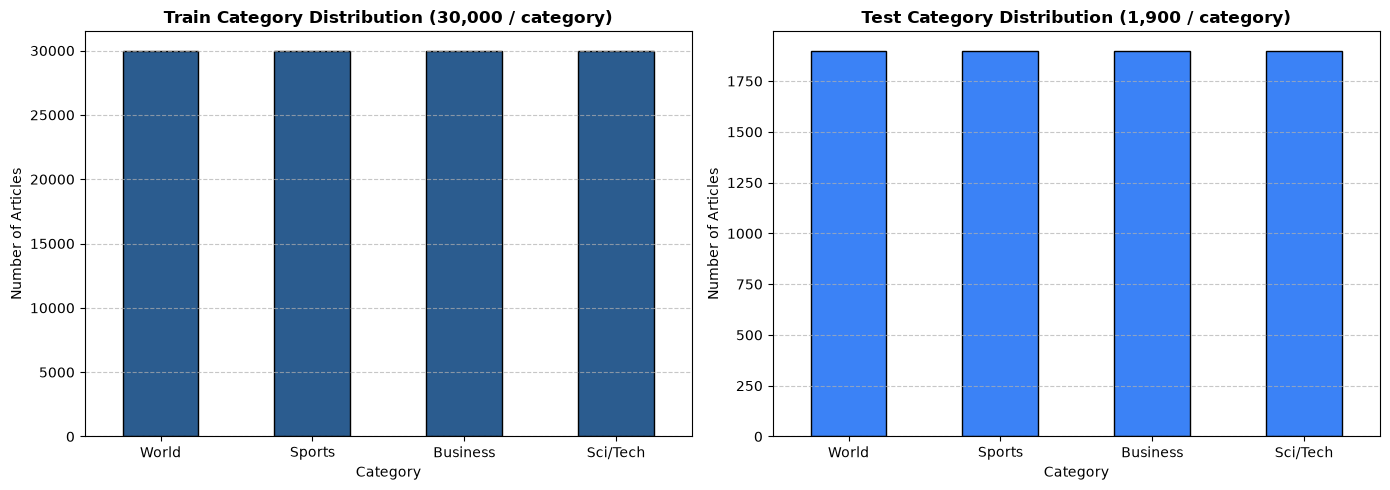

In [8]:
# 1. Category Distribution Bar Chart (Train vs Test)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

train_df["category"].value_counts().reindex(category_order).plot(
    kind="bar", ax=axes[0], color="#2b5c8f", edgecolor="black", rot=0
)
axes[0].set_title("Train Category Distribution (30,000 / category)", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Category")
axes[0].set_ylabel("Number of Articles")
axes[0].grid(axis="y", linestyle="--", alpha=0.7)

test_df["category"].value_counts().reindex(category_order).plot(
    kind="bar", ax=axes[1], color="#3b82f6", edgecolor="black", rot=0
)
axes[1].set_title("Test Category Distribution (1,900 / category)", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Category")
axes[1].set_ylabel("Number of Articles")
axes[1].grid(axis="y", linestyle="--", alpha=0.7)

plt.tight_layout()
plt.show()

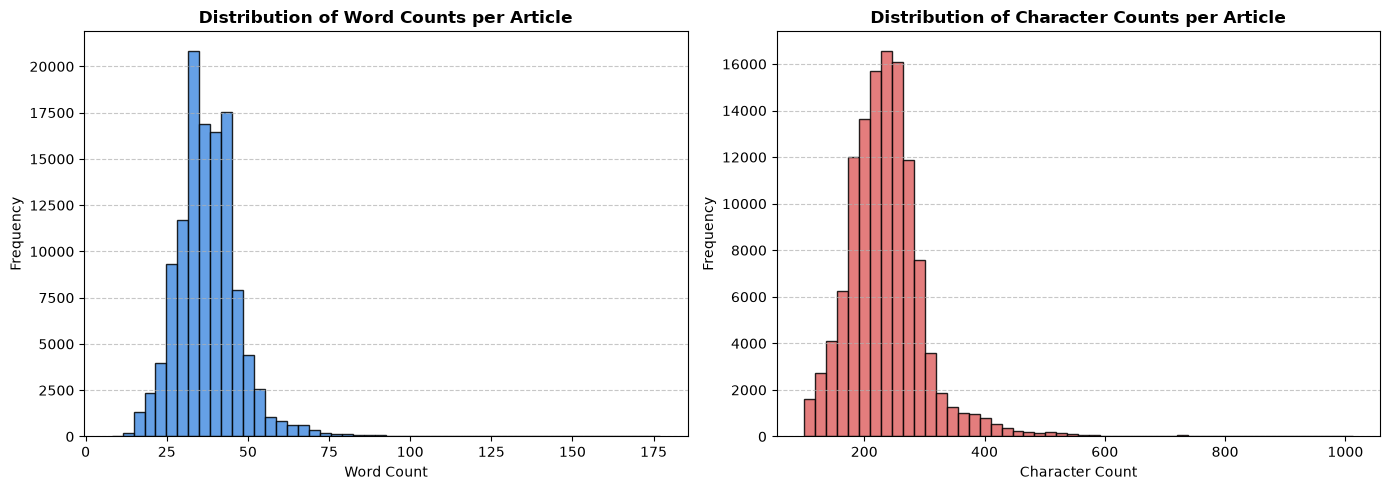

C:\Users\Acer\AppData\Local\Temp\ipykernel_11648\3416283955.py:21: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(train_df["word_count"], vert=False, flierprops=dict(marker="o", markersize=3, alpha=0.4, color="#e06666"))


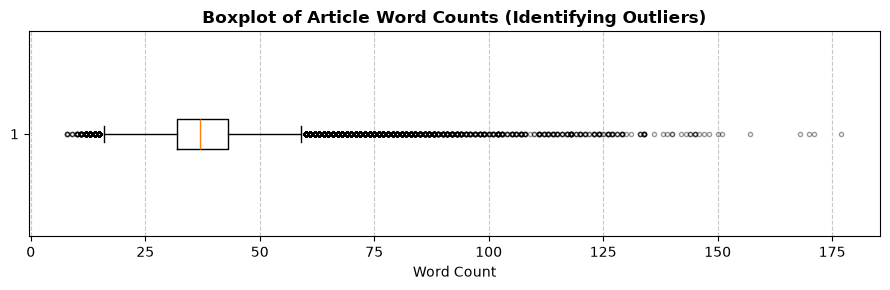

In [9]:
# 2. Text Length Distributions (Histograms and Boxplot)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(train_df["word_count"], bins=50, color="#4a90e2", edgecolor="black", alpha=0.85)
axes[0].set_title("Distribution of Word Counts per Article", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Word Count")
axes[0].set_ylabel("Frequency")
axes[0].grid(axis="y", linestyle="--", alpha=0.7)

axes[1].hist(train_df["char_count"], bins=50, color="#e06666", edgecolor="black", alpha=0.85)
axes[1].set_title("Distribution of Character Counts per Article", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Character Count")
axes[1].set_ylabel("Frequency")
axes[1].grid(axis="y", linestyle="--", alpha=0.7)

plt.tight_layout()
plt.show()

# Boxplot for outliers
plt.figure(figsize=(9, 3))
plt.boxplot(train_df["word_count"], vert=False, flierprops=dict(marker="o", markersize=3, alpha=0.4, color="#e06666"))
plt.title("Boxplot of Article Word Counts (Identifying Outliers)", fontsize=12, fontweight="bold")
plt.xlabel("Word Count")
plt.grid(axis="x", linestyle="--", alpha=0.7)
plt.tight_layout()
plt.show()

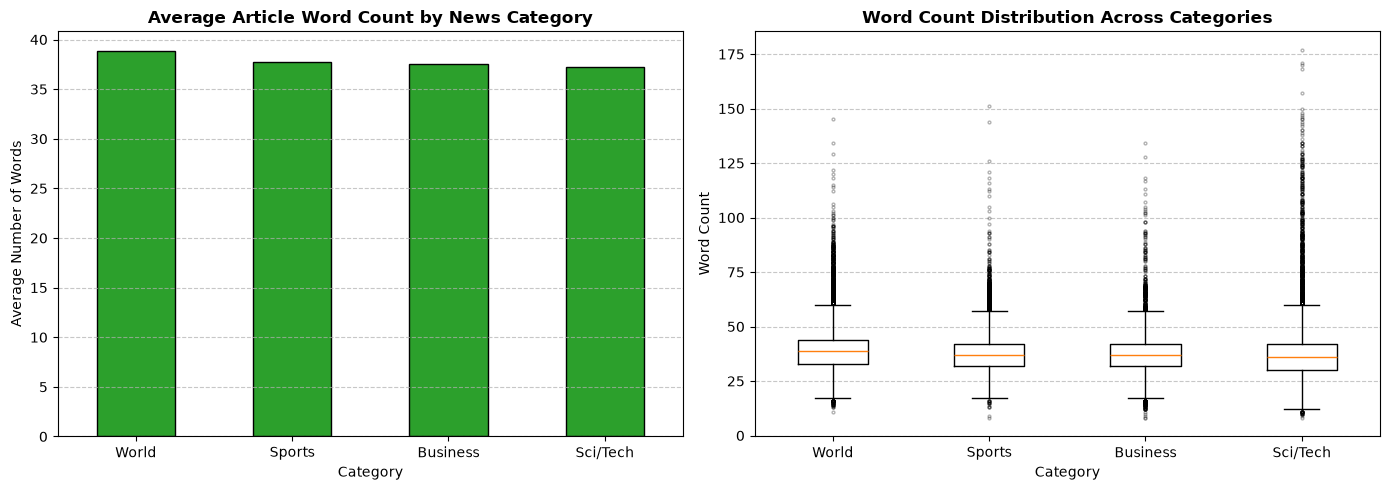

In [10]:
# 3. Word Count Comparison Across Categories (Bar chart & Boxplot)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

category_means.plot(kind="bar", ax=axes[0], color="#2ca02c", edgecolor="black", rot=0)
axes[0].set_title("Average Article Word Count by News Category", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Category")
axes[0].set_ylabel("Average Number of Words")
axes[0].grid(axis="y", linestyle="--", alpha=0.7)

data_by_cat = [train_df[train_df["category"] == cat]["word_count"].values for cat in category_order]
axes[1].boxplot(data_by_cat, tick_labels=category_order, flierprops=dict(marker="o", markersize=2, alpha=0.3))
axes[1].set_title("Word Count Distribution Across Categories", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Category")
axes[1].set_ylabel("Word Count")
axes[1].grid(axis="y", linestyle="--", alpha=0.7)

plt.tight_layout()
plt.show()

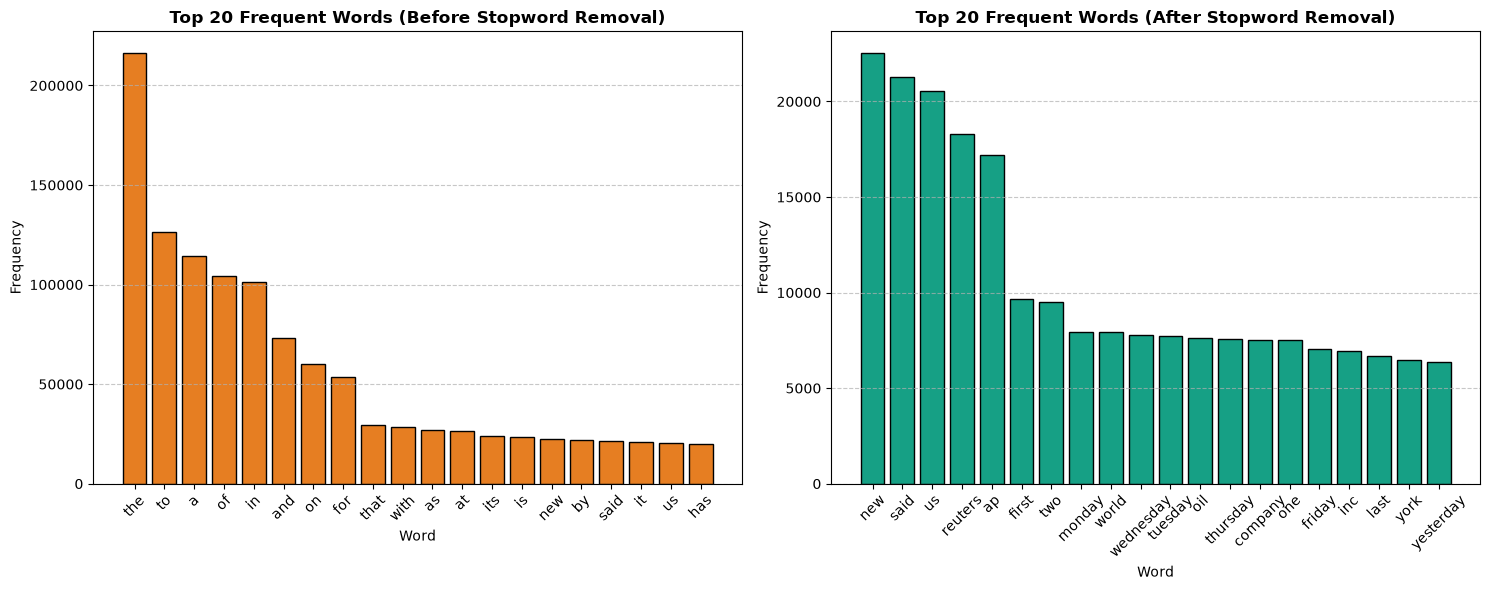

In [11]:
# 4. Word Frequency Comparison: Before vs. After Stopword Removal
words_raw, counts_raw = zip(*top_20)
words_flt, counts_flt = zip(*top_20_filtered)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

axes[0].bar(words_raw, counts_raw, color="#e67e22", edgecolor="black")
axes[0].set_title("Top 20 Frequent Words (Before Stopword Removal)", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Word")
axes[0].set_ylabel("Frequency")
axes[0].tick_params(axis="x", rotation=45)
axes[0].grid(axis="y", linestyle="--", alpha=0.7)

axes[1].bar(words_flt, counts_flt, color="#16a085", edgecolor="black")
axes[1].set_title("Top 20 Frequent Words (After Stopword Removal)", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Word")
axes[1].set_ylabel("Frequency")
axes[1].tick_params(axis="x", rotation=45)
axes[1].grid(axis="y", linestyle="--", alpha=0.7)

plt.tight_layout()
plt.show()

## 8. Exploration Findings

### Summary of Key Findings:

1. **Dataset Size and Perfect Class Balance**:
   - **Training set**: 120,000 articles, exactly 30,000 articles per category (25% each).
   - **Test set**: 7,600 articles, exactly 1,900 articles per category (25% each).
   - Both subsets are perfectly balanced across the 4 news classes: `World`, `Sports`, `Business`, and `Sci/Tech`. Standard evaluation metrics such as macro-averaged F1 and accuracy will be reliable without requiring resampling techniques.

2. **Missing Values & Data Integrity**:
   - Missing values: **0** across all columns (`text`, `label`, `category`).
   - No null or empty text records exist in either split.

3. **Duplicates & Data Leakage**:
   - There are **0 repeated article texts** within the training set and **0 repeated article texts** within the test set.
   - There is **0 overlap (data leakage)** between train and test splits, ensuring an uncontaminated evaluation benchmark.

4. **Text Length Characteristics**:
   - Articles have an average word count of approximately **37.8 words** (median = 37 words, standard deviation = 10.1 words).
   - Word counts range from a minimum of **8 words** to a maximum of **177 words**.
   - Interquartile Range (IQR): 25th percentile is 32 words and 75th percentile is 43 words. Articles are relatively concise headlines and summaries.
   - Average article length across categories is remarkably consistent: all categories average between 35 and 40 words.

5. **Vocabulary & Stopword Insights**:
   - Prior to stopword removal, the most frequent tokens are common English grammatical terms (`the`, `a`, `to`, `of`, `in`, `and`, `on`).
   - After removing standard English stopwords, informative news vocabulary emerges, such as `said`, `new`, `us`, `reuters`, `ap`, `first`, `two`, `company`, and `world`.
   - Source indicators like `reuters` and `ap` (Associated Press) frequently appear in article texts and will be relevant for preprocessing and classification considerations.

6. **Next Steps for NewsScope Pipeline**:
   - **Text Preprocessing**: Cleaning, lowercasing, punctuation and symbol removal, and stopword filtering.
   - **Feature Extraction**: TF-IDF vectorization and word embeddings.
   - **Machine Learning**: Supervised news classification (e.g., Logistic Regression, Naive Bayes, Linear SVM), unsupervised clustering (K-Means), and topic modeling (LDA / NMF).